### Anna Horton's Cartography w/ MatplotLib part 1 homework
ONYEN: Anna Horton
PID: 730664552

#### First task: choose a species narrative
I chose the upland sandpiper and the piping plover to compare. After living on the Outer Banks for six months of the last year, I have become largely familiar with the birds that live in these areas, and the small birds that run away from the waves are often subjects of fascination. Many people confuse the sandpiper and the piping plover, and I hope to provide a differentiation between the two.        
I honestly got the idea when looking at the bird migration map that I have on the wall in my bedroom.             

In [27]:
## loading in the data from GBIF - both the green sea turtle and the Kemp's ridley sea turtle are included in this query
# https://www.gbif.org/

## importing the required packages
import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## calling the specific species
species = ["Bartramia longicauda", "Charadrius melodus"]
year = 2026

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # 1. Find the GBIF taxon identifier for the scientific name.
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60 # the parameter that ensure that the timeout happens after 60 seconds
    )
    response.raise_for_status()
    match = response.json()

    if (
        match.get("matchType") != "EXACT" ## asking for exact matches in the species name from the GBIF database
        or match.get("rank") != "SPECIES"
    ):
        raise ValueError(f"Check the species name: {name}") ## raising a ValueError if the species name doesn't match, which raises the error and does not stop the execution of the code

    taxon_key = match.get("acceptedUsageKey", match["usageKey"]) ## create a databse with keys

    # 2. Define which occurrence records to request.
    parameters = { ## only keep what you need
        "taxonKey": taxon_key,
        "country": "US", ## removed the N.C. term, as we want to be able to pull for the entire continent of the United States
        "year": year,
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    # 3. Retrieve successive pages of records.
    species_records = [] 

    while True: ## while there are still pages of records, keep going
        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status() ## allows for the HTTP to demonstrate errors that arose within the execution of the code
        page = response.json()

        # LIMIT THE NUMBER OF CASES (you can change it but, the larger the number...the longer the wait)
        ## depending on run time, I might adjust this, but I honestly think that these turtles are so tough to observe that it'll be fine
        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records for this example. "
                "Narrow the date range or use a GBIF bulk download."
            ) ## I can tell it's too big based on the time it takes to query

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break # if we get to the end, break!

        parameters["offset"] += len(page["results"])
        time.sleep(0.2) ## suspends execution for .2 seconds to create the offset parameter

    records.extend(species_records) ## extending the original records object with the species records
    print(f"{name}: {len(species_records):,} records") ## f string printing the results

Bartramia longicauda: 416 records
Charadrius melodus: 1,759 records


In [28]:
## making a dataframe of the records that the above code pulled
birds = pd.DataFrame(records)
birds = birds[["queried_species", "decimalLongitude", "decimalLatitude"]] ## only selected the columns that I needed from the largest DF
birds.head()

,queried_species,decimalLongitude,decimalLatitude
0,Bartramia longicauda,-97.673447,26.180535
1,Bartramia longicauda,-96.385709,29.666958
2,Bartramia longicauda,-97.799064,26.116228
3,Bartramia longicauda,-97.687000,26.696000
4,Bartramia longicauda,-97.637251,29.074843


After running this code, it appears that there are a mere 416 records of the upland sandpiper and 1,759 records of the piping plover in 2026. There is a marked difference here, so I believe that the chloropleth maps will be distinct. 

Now, I will pull in the census data for the state level boundaries. 

<Axes: >

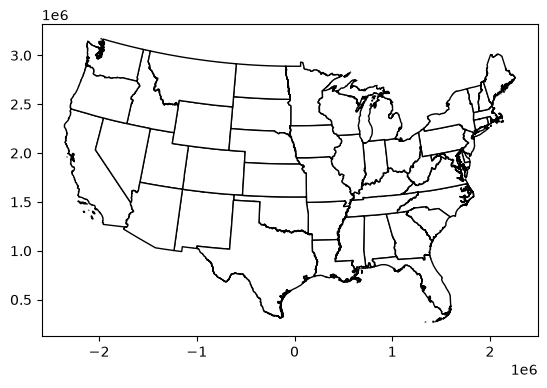

In [29]:
# getting the US census data for the outlines of the states

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census TIGER data (this is the direct URL copied from the website)
url_state = "cb_2024_us_state_500k.zip" # state level 
## can divide the URL into two pieces to manipulate them in a loop or something similar is useful
## removed all county level data, as I don't require that

## remove Alaska, Hawaii and the other states that make mapping difficult as they are not part of the lower 48
states = gpd.read_file(url_0+url_state) ## concatenation of the two types of urls
contiguous_us = states.loc[
    ~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])
] ## removing all of the states that are not within the lower 48 for ease of plotting

contiguous_us = contiguous_us.to_crs(epsg=5070) ## changing the CRS of the contiguous US
contiguous_us.plot(edgecolor="black", facecolor="white") ## creating a plot of the land area

## had to ask AI as I was getting an issue with the URL not opening (turns out I had to install a package from the Finder for it to work)

Next, I need to make a gpd databse from the x and y data for the bird points so that they are eventually able to be placed on a map.

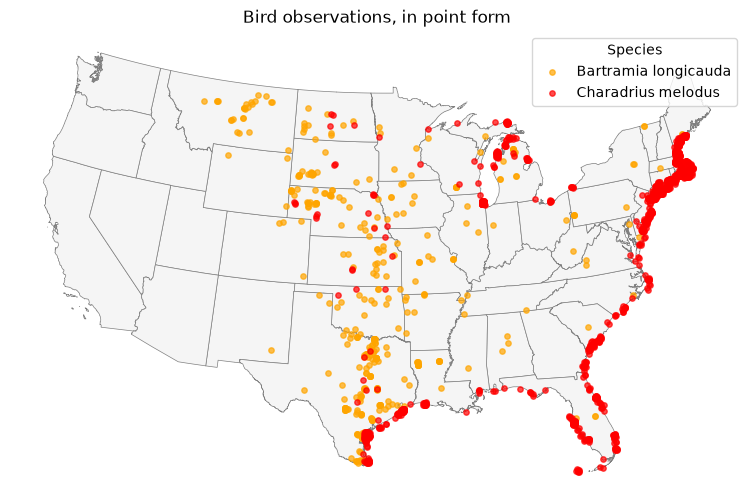

In [30]:
## make a gdp from the x and y data - need to keep the x and y to make points on the map 
bird_points = gpd.GeoDataFrame(
    birds.copy(),
    geometry=gpd.points_from_xy( ## the method is calleed points_from_xy
        birds["decimalLongitude"], # x
        birds["decimalLatitude"] # y
        ),
    crs="EPSG:4326" # often the crs is in 4326 if it is a lat lon coordinate, the default geographic coordinate system
    )

bird_points = bird_points.to_crs(epsg=5070) ## converting it into the same EPSG as the U.S. state data

fig, ax = plt.subplots(figsize=(12, 6))
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Bartramia longicauda" : "orange", "Charadrius melodus": "red"}

for species, color in colors.items():
    bird_points.loc[
        bird_points["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title("Bird observations, in point form")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

Next I will use a spatial join (and spatial predicate within) to ask for the number of observations within a state's boundaries.

In [31]:
## now we need to create a count of the observations collected in each state
## by using a spatial join, we are able to pull dataframes together spatially (w/ x and y) as opposed to a shared category
points_by_state = gpd.sjoin(
    bird_points,
    contiguous_us[["NAME", "geometry"]], ## joining the bird_points data and only the name and geometry columns of the contigouous U.S. dataset that I established earlier
    how="inner",
    predicate="within" ## asking for which points are WITHIN the boundaries of each state
).drop(columns="index_right") ## dropping the right index column entirely

## This code pulls the two databases together so that the data from both can be used. 

## also creating a counts column for the states
counts = (
    points_by_state
    .groupby(["NAME", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Bartramia longicauda", "Charadrius melodus"], fill_value=0)
)

points_by_state.head()

,queried_species,decimalLongitude,decimalLatitude,geometry,NAME
0,Bartramia longicauda,-97.673447,26.180535,POINT (-168710.501 349044.969),Texas
1,Bartramia longicauda,-96.385709,29.666958,POINT (-37325.541 732506.248),Texas
2,Bartramia longicauda,-97.799064,26.116228,POINT (-181506.972 342214.259),Texas
3,Bartramia longicauda,-97.687000,26.696000,POINT (-169070.828 405727.72),Texas
4,Bartramia longicauda,-97.637251,29.074843,POINT (-159561.741 668192.867),Texas


This code represents the first, basic chloropleth map that is made. Further classification schemes will be created. 

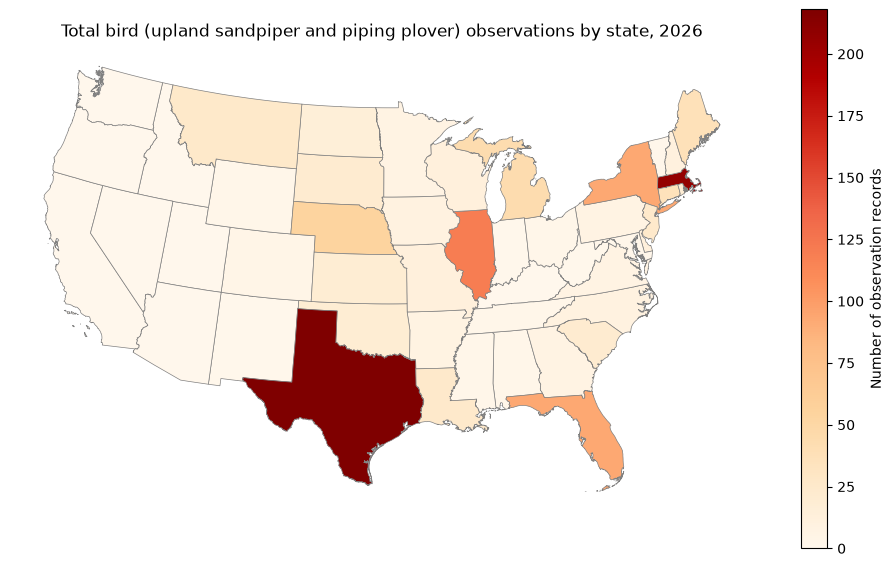

In [32]:
## creating my first chloropleth map
def choroplethMap(ax, contiguous_us, counts):
    # Total observations per state.
    totals = counts.sum(axis=1).rename("total") # using the counts() method to count the total number of observations that relate to each state and then summarizing them in the table

    # Join totals to the state polygons
    state_map = contiguous_us.merge(
        totals,
        left_on="NAME",
        right_index=True,
        how="left"
    )

    # States without records receive zero - will not be assigned a color on the final map
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        cmap="OrRd", ## made this into an orange/red color scheme
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Number of observation records"},
        ax=ax
    )

    ax.set_title("Total bird (upland sandpiper and piping plover) observations by state, 2026")
    ax.set_axis_off()

    return ax

fig, ax = plt.subplots(figsize=(12, 7))

choroplethMap(ax, contiguous_us, counts)

plt.show()

Below is the code for each of the classification schemes for the chloropleth map. 

In [33]:
%pip install mapclassify ## this was needed, as I didn't have the mapclassify package loaded in my code

# refers to the equal interval chloropleth map
def choroplethEqual(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total") ## refers to the total counts of observations assigned to each state

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0) ## if a state doesn't have any data, the code fills the NA/NaN with a zero

    state_map.plot(
        column="total",
        scheme="equalinterval",
        k=5,
        cmap="OrRd", ## using the orange/red color scheme again
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 9},
        ax=ax
    )

    ax.set_title("Equal Interval Plover and Sandpiper Observations, 2026")
    ax.set_axis_off()
    return ax

Note: you may need to restart the kernel to use updated packages.


In [34]:
def choroplethQuantiles(ax, contiguous_us, counts): ## refers to the quantile breaks
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="quantiles",
        k=5,
        cmap= "OrRd", ## using orange/red to ensure that there is cohesiveness
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 9},
        ax=ax
    )

    ax.set_title("Quantile Plover and Sandpiper Observations. 2026")
    ax.set_axis_off()
    return ax

In [35]:
def choroplethNatural(ax, contiguous_us, counts): ## refers to the natural breaks/jenks chloropleth classification scheme
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="fisherjenks",
        k=5,
        cmap="OrRd", ## if individual, I would use another scheme, but the orange/red looks cohesive when they are all on the map together
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 9},
        ax=ax
    )

    ax.set_title("Natural breaks (Fisher–Jenks) Plover and Sandpiper Observations, 2026")
    ax.set_axis_off()
    return ax


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/geopandas/plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


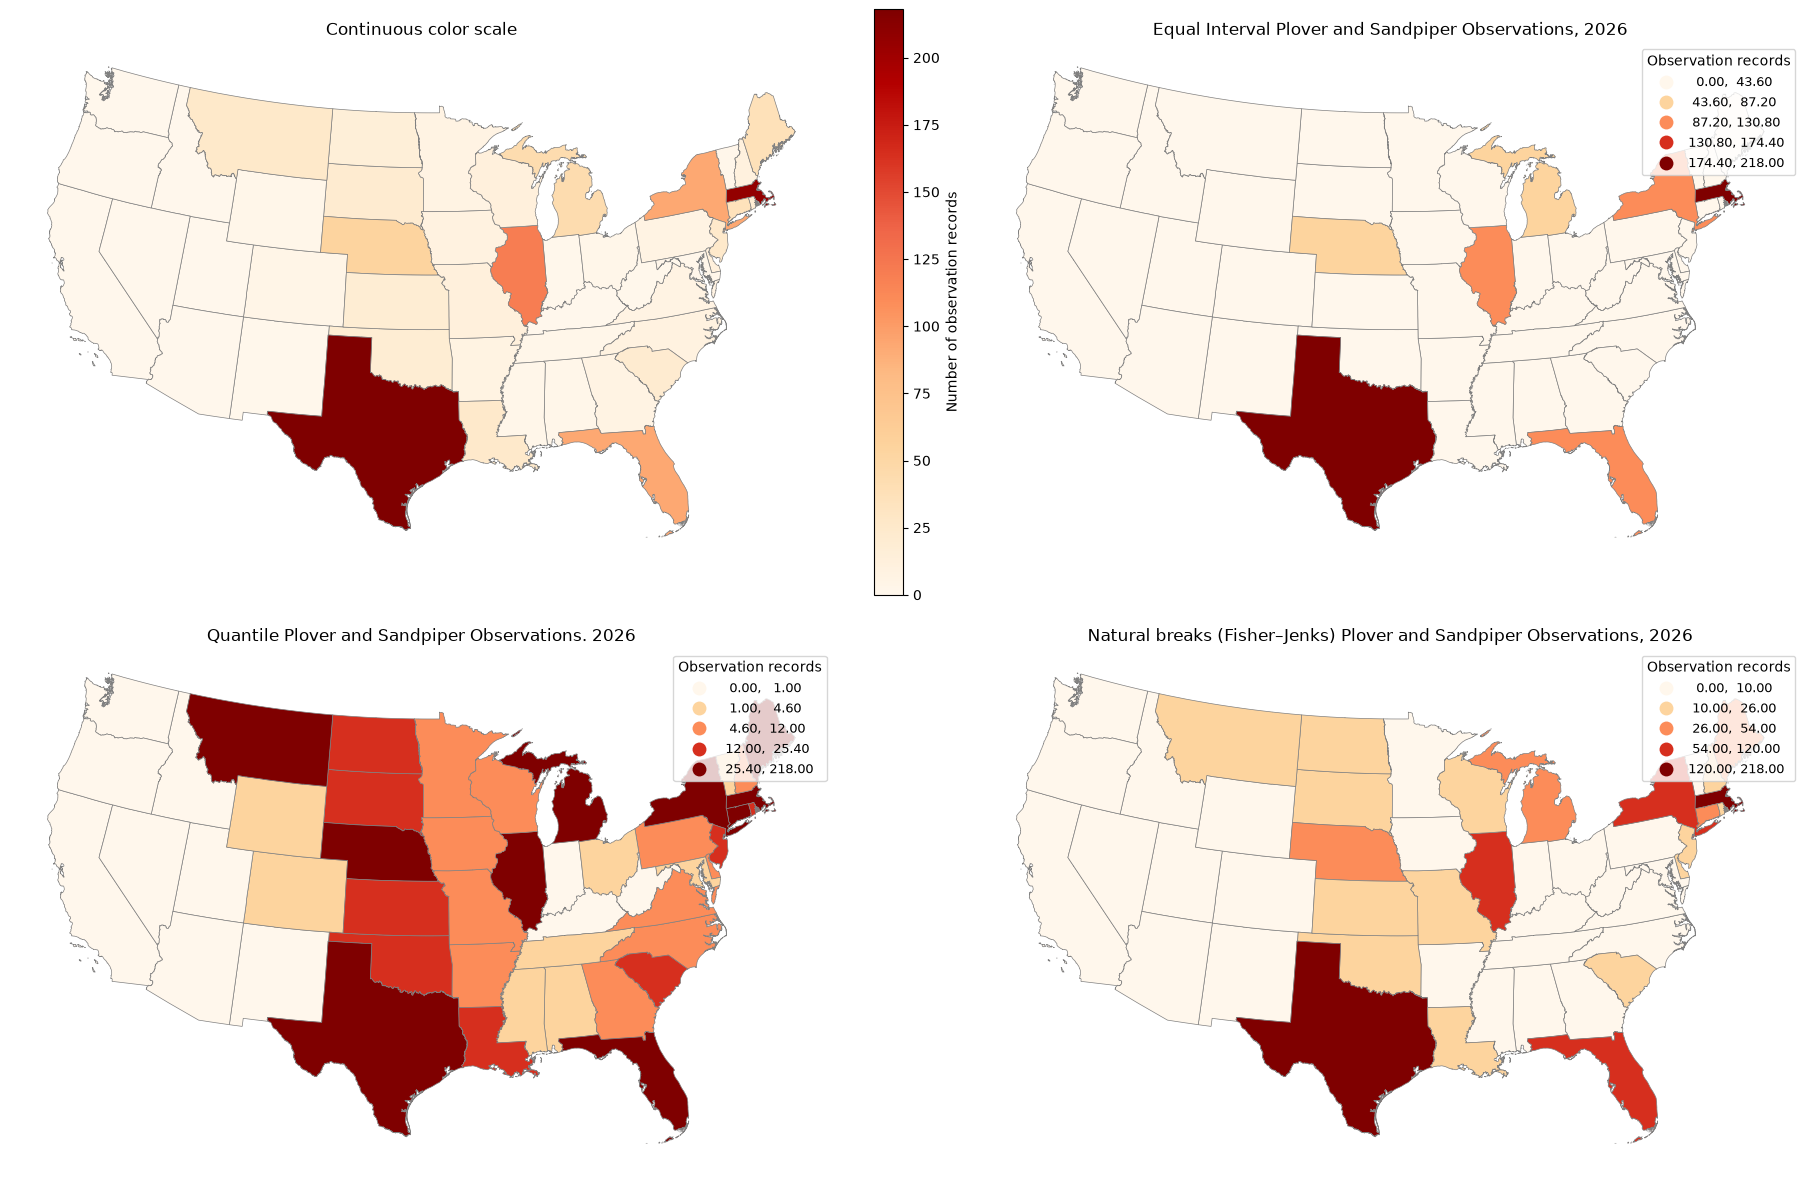

In [36]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
) ## allows for there to be four different maps within the boundaries of the same figure

choroplethMap(axes[0, 0], contiguous_us, counts)
axes[0, 0].set_title("Continuous color scale") ## sets the title and boundaries for the first map, the continous color scale

choroplethEqual(axes[0, 1], contiguous_us, counts) # set the position, the background, and the variable plotted for each chloropleth
choroplethQuantiles(axes[1, 0], contiguous_us, counts)
choroplethNatural(axes[1, 1], contiguous_us, counts)

fig.savefig("bird.png", dpi=300, bbox_inches="tight") # exposes the title, the dpi, and the bounding box inches, this code exports the figure as a png
plt.show()

I think that the natural breaks classification gets at the natural breaks of the species presence data well. The individuals of each species that are being observed are not static, and so utilizing a statistical technique that gets at those obvious breaks is important. 

The code below prints out a PNG of a bivariate map of piping plover and upland sandpiper observations in 2026. 

Bartramia longicauda positive-count median: 3.0
Charadrius melodus positive-count median: 10.0


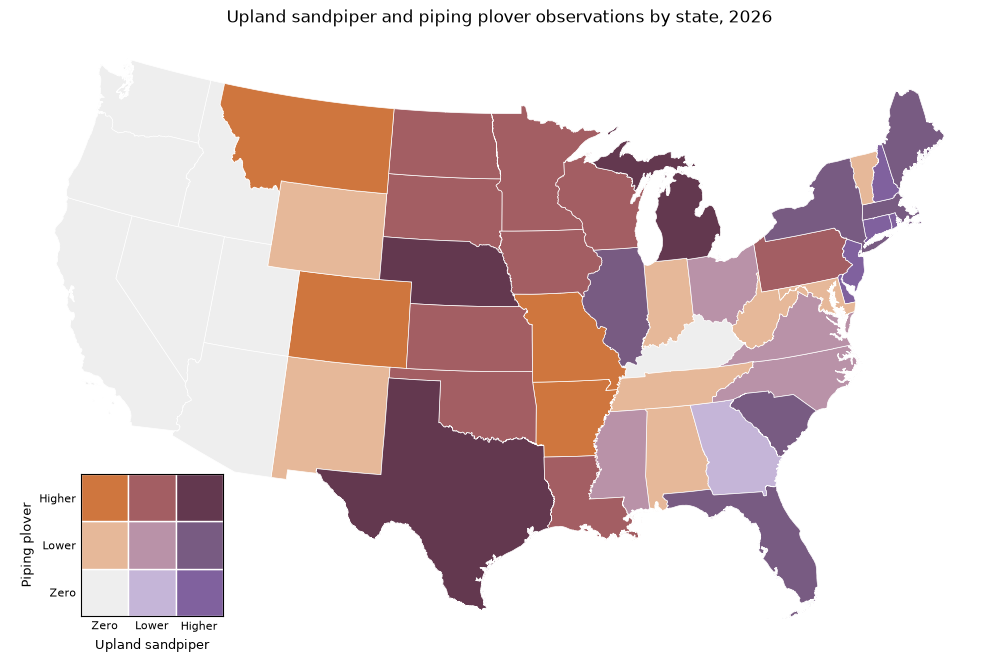

In [37]:
## bivariate map code below

import numpy as np
from matplotlib.patches import Rectangle

# Attach each species' counts to the state polygons - important step that I don't quite understand how I didn't do earlier?
bivariate = contiguous_us.merge(
    counts,
    left_on="NAME",
    right_index=True,
    how="left"
)

species = ["Bartramia longicauda", "Charadrius melodus"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species:
# 0 = no records
# 1 = positive count at or below the positive-count median
# 2 = count above that median
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)

palette = np.array([
    ["#eeeeee", "#c5b5d8", "#80619e"],
    ["#e6b899", "#b992a8", "#785b82"],
    ["#cf763e", "#a35e63", "#63384f"]
])

bivariate["color"] = [
    palette[sandpiper, plover]
    for sandpiper, plover in zip(
        bivariate["Bartramia longicauda_class"], ## reassigning these variables for my two birds
        bivariate["Charadrius melodus_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8)) ## codes for the 13 and 8 bounds of the figure

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
) 

ax.set_title("Upland sandpiper and piping plover observations by state, 2026")
ax.set_axis_off()

# Add a 3 × 3 bivariate legend so that the palette makes sense
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for sandpiper in range(3):
    for plover in range(3):
        legend_ax.add_patch(
            Rectangle(
                (plover, sandpiper), 1, 1,
                facecolor=palette[sandpiper, plover],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("Upland sandpiper", fontsize=9)
legend_ax.set_ylabel("Piping plover", fontsize=9)
legend_ax.tick_params(length=0)

plt.show()

The western part of the United States (California, Washington, Oregon, etc.) does not posess any data, which means that neither of the two species are found there. Texas, on the other hand, is the state with the highest amount of observations of both the upland sandpiper and the pipiing plover. Michigan and Nebraska also posess high species counts. 
North Caroilna is in the middle for both (the light purple hue), which I find surprising given the Outer Banks and the amount of migratory birds we see every year. 

In [38]:
## exporting this map as a png as well
fig.savefig("bird_bivariae.png", dpi=300, bbox_inches="tight")

The limitations of using classification schemes for chloropleth maps representing the distribution of species relate to the likely errors involved in capturing the species presence of migratory species and the possibility that these individuals are not specifically located within state boundaries; however, they can be an easy way to represent which states contain more of the species of interest and should be prioritizing them more. Migratory species might be captued in one location one month and be in a completely different location the next, which could lead to duplicate observations (this is an issue regardless of migration, but it is compounded by their directional relocation). With scientific data, the amount of errors need to be diminished as completely as possible, and this is a large source of error. Additionally, animals don't care about state lines and often roam around and near them. The individuals who are recording these observations are sometimes being forced to make a subjective decision about state presence, which can skew the data. Notably, however, chloropleth maps can be used as a very simple "where is this species, on average?" tool. The states that have a higher presence of the species based on the chloropleth map should consider prioritizing and/or taking care of that species more than a species which might not have as much of a documented presence. 

The natural breaks classification scheme likely is the most accurate scheme because it uses statistics to get at the 'natural' breaks in the data, without forcing data to be in any particular category. These species of birds tend to migrate, so having the natural breaks scheme allows for that movement to illustrate key breaks in the data. 

AI statement
1) I used Claude AI.
2) I had a quick issue with pulling in the census data. 
3) I asked it to help me diagnose the URL error I was getting, as I had never seen anything like that before. 
4) I didn't change anything in the code, I just went into my Finder, installed the appropriate certificate, and all was well. 